In [ ]:
import io
import chess.pgn
import pandas as pd
import zstandard as zstd

FICHIER = "../lichess_db_standard_rated_2026-09.pgn.zst"
NB_PARTIES_MAX = 50_000

donnees = []

with open(FICHIER, "rb") as fichier:
    decompresseur = zstd.ZstdDecompressor()
    with decompresseur.stream_reader(fichier) as lecteur:
        texte = io.TextIOWrapper(lecteur, encoding="utf-8")

        for _ in range(NB_PARTIES_MAX):
            header = chess.pgn.read_headers(texte)
            if header is None:
                break

            donnees.append(
                {
                    "white": header.get("White"),
                    "black": header.get("Black"),
                    "white_elo": header.get("WhiteElo"),
                    "black_elo": header.get("BlackElo"),
                    "result": header.get("Result"),
                    "time_control": header.get("TimeControl"),
                    "termination": header.get("Termination"),
                    "eco": header.get("ECO"),
                    "opening": header.get("Opening"),
                    "ply_count": header.get("PlyCount"),
                }
            )

df = pd.DataFrame(donnees)

df["white_elo"] = pd.to_numeric(df["white_elo"], errors="coerce")
df["black_elo"] = pd.to_numeric(df["black_elo"], errors="coerce")
df["ply_count"] = pd.to_numeric(df["ply_count"], errors="coerce")

df["avg_elo"] = (df["white_elo"] + df["black_elo"]) / 2
df["nb_coups"] = df["ply_count"] // 2

Dimensions du dataset : (50000, 12)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
white,50000,27536,brutalbishop31,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
black,50000,27521,brutalbishop31,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
white_elo,50000.0,NaN,NaN,NaN,1643.35508,401.750269,400.0,1364.0,1659.0,1924.0,3108.0
black_elo,50000.0,NaN,NaN,NaN,1643.69358,402.040464,400.0,1363.0,1660.0,1925.0,3058.0
result,50000,4,1-0,24820,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_control,50000,134,60+0,13612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
termination,50000,6,Normal,33071,NaN,NaN,NaN,NaN,NaN,NaN,NaN
eco,50000,403,A40,3134,NaN,NaN,NaN,NaN,NaN,NaN,NaN
opening,50000,1727,Queen's Pawn Game,1463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ply_count,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,valeurs manquantes (%)
ply_count,100.0
nb_coups,100.0
white,0.0
black,0.0
black_elo,0.0
white_elo,0.0
result,0.0
time_control,0.0
eco,0.0
termination,0.0


Matplotlib is building the font cache; this may take a moment.


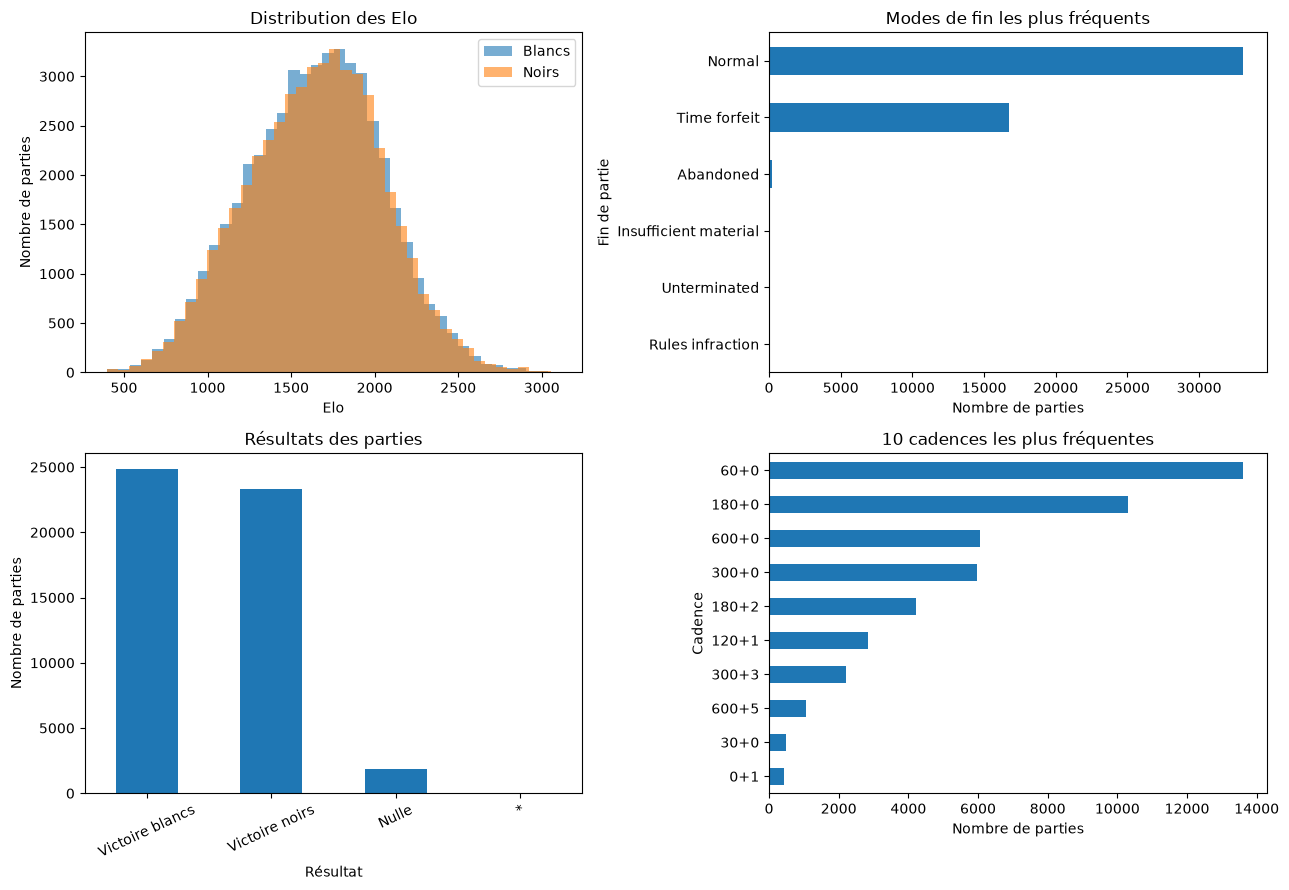

In [ ]:
print("Dimensions du dataset :", df.shape)
display(df.describe(include="all").T)
display((df.isna().mean() * 100).sort_values(ascending=False).rename("valeurs manquantes (%)").to_frame())

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
# test
for colonne, nom in [("white_elo", "Blancs"), ("black_elo", "Noirs")]:
    df[colonne].dropna().plot.hist(bins=40, alpha=0.6, ax=axes[0, 0], label=nom)
axes[0, 0].set(title="Distribution des Elo", xlabel="Elo", ylabel="Nombre de parties")
axes[0, 0].legend()

df["termination"].value_counts().head(8).sort_values().plot.barh(ax=axes[0, 1])
axes[0, 1].set(title="Modes de fin les plus fréquents", xlabel="Nombre de parties", ylabel="Fin de partie")

resultats = df["result"].value_counts(dropna=False).rename(
    index={"1-0": "Victoire blancs", "0-1": "Victoire noirs", "1/2-1/2": "Nulle"}
)
resultats.plot.bar(ax=axes[1, 0])
axes[1, 0].set(title="Résultats des parties", xlabel="Résultat", ylabel="Nombre de parties")
axes[1, 0].tick_params(axis="x", rotation=25)

df["time_control"].value_counts().head(10).sort_values().plot.barh(ax=axes[1, 1])
axes[1, 1].set(title="10 cadences les plus fréquentes", xlabel="Nombre de parties", ylabel="Cadence")

plt.tight_layout()
plt.show()